# **3. Decodificando CatBoost y el Ecosistema Híbrido**



*Fig. 3.1. El tipo de boosting y la política de crecimiento son configurables.*

Gradient boosting con árboles es un método supervisado y aditivo. CatBoost, publicado por Yandex en 2017 y descrito en NeurIPS 2018, introduce estadísticas ordenadas para categorías y un esquema de boosting ordenado que reduce una fuente concreta de *prediction shift*. Son mecanismos distintos y configurables; no eliminan todas las formas de fuga de información ni todo sobreajuste.



*Fig. 3.2. El artículo de CatBoost analiza mecanismos concretos de prediction shift.*

## 3.1. Target encoding y fuga de información

Una categoría puede codificarse con una media suavizada del objetivo:

$$\hat x_i=\frac{\sum_j\mathbb{I}[x_j=x_i]y_j+s p}{\sum_j\mathbb{I}[x_j=x_i]+s},\qquad s>0.$$

$p$ es un prior y $s$ su peso. Si la categoría aparece una sola vez, el resultado es $(y_i+s p)/(1+s)$; **solo sin suavizado** se obtiene exactamente $y_i$. Incluir el propio objetivo en el atributo introduce fuga aunque haya suavizado. Para evaluación honesta se usan estadísticas fuera de pliegue o un procedimiento ordenado y priors que no consulten las etiquetas de validación o test.

## 3.2. Prediction shift

El gradiente de una etapa es

$$g_i^{(t)}=\left.\frac{\partial L(y_i,s)}{\partial s}\right|_{s=F_{t-1}(x_i)}.$$

El nuevo aprendiz aproxima su **negativo**. El signo de esta definición es importante: $g$ y el pseudo-residuo $-g$ no son lo mismo.

### 3.2.1. Dependencia del objetivo propio

Si $F_{t-1}$ se entrenó con la observación $i$, su predicción en $x_i$ depende del propio $y_i$. Por eso los gradientes calculados sobre entrenamiento pueden tener una distribución distinta de los obtenidos para una observación nueva, incluso condicionando por sus atributos. El artículo de CatBoost estudia esta fuente de desplazamiento. No debe confundirse con un cambio temporal de la distribución de datos ni afirmarse que invalida cualquier boosting convencional.

## **3.3. Las Soluciones Matemáticas de CatBoost**



*Fig. 3.3. Son componentes diferentes; no equivalen a ausencia total de sobreajuste.*

### **3.3.1 Ordered Target Statistics (Estadísticas de Objetivo Ordenadas)**



*Fig. 3.4. El orden artificial no debe confundirse con tiempo físico.*

CatBoost construye estadísticas usando una permutación $\sigma$. Para una muestra en la posición $i$, una versión simplificada es

$$S_{\sigma(i)}=\frac{\sum_{j<i}\mathbb{I}[x_{\sigma(j)}=x_{\sigma(i)}]y_{\sigma(j)}+a p}{\sum_{j<i}\mathbb{I}[x_{\sigma(j)}=x_{\sigma(i)}]+a},\qquad a>0.$$

El objetivo propio no entra en las sumas. Con un prior fijado independientemente de ese objetivo, se evita esa dependencia directa. Calcular el prior con todos los objetivos, incluido el propio, reintroduciría una dependencia indirecta. En datos temporales o agrupados también hay que respetar la partición y el orden pertinentes.



*Fig. 3.5. El prior del ejemplo se fija independientemente del objetivo propio.*

| Símbolo | Significado |
|---|---|
| $\sigma(i)$ | Muestra en la posición $i$ de una permutación; no es tiempo físico. |
| $j<i$ | Solo observaciones anteriores en ese orden. |
| $N_{c,<i}$ | Número de observaciones previas de la categoría $c$. |
| $p$ | Prior fijado sin consultar la etiqueta propia ni etiquetas retenidas para evaluación. |
| $a>0$ | Peso del prior; no se exige en general que sea mayor o igual que 1. |

#### 3.3.1.1. Interpretación de la codificación

##### 1. Una categoría, distintas historias disponibles

La media por categoría asigna un mismo valor a todas sus observaciones de entrenamiento. En la codificación ordenada, cada observación tiene un historial distinto y puede recibir otro valor. Esta secuencia es una herramienta estadística: no constituye una trayectoria causal ni una prueba de una variedad topológica.

##### 2. Suavizado hacia el prior

Con $N=N_{c,<i}>0$,

$$S_{\sigma(i)}=(1-\lambda_i)p+\lambda_i\bar y_{c,<i},\qquad\lambda_i=\frac{N}{N+a}.$$

Si $N=0$, se utiliza $p$ y no se calcula una media vacía. Al crecer $N$, disminuye el peso relativo del prior. La convergencia a una esperanza condicional requiere supuestos de muestreo y estabilidad de la distribución; no es una garantía para cualquier dataset.

#### 3.3.1.2. Traza numérica

Usamos cinco observaciones, un prior **fijo** $p=0.40$ y $a=1$. El 0.40 es un valor elegido para el ejemplo, no la media de sus cinco objetivos, que es 0.60.



*Fig. 3.6. La media de los cinco objetivos es 0,60; no es el prior elegido.*

##### **1. Paso a Paso del Cálculo Causal**

* **Paso 1 ($p=1$, Muestra $\sigma_1 =$ ID 1, `"Salta"`):**

    * Historial previo de `"Salta"`: $\text{Conteo } N = 0$, $\text{Suma Targets } S = 0$.

$$\hat{x}_{\sigma_1} = \frac{0 + 1.0 \cdot 0.40}{0 + 1.0} = \mathbf{0.400}$$

---

* **Paso 2 ($p=2$, Muestra $\sigma_2 =$ ID 2, `"Jujuy"`):**

    * Historial previo de `"Jujuy"`: $\text{Conteo } N = 0$, $\text{Suma Targets } S = 0$.

$$\hat{x}_{\sigma_2} = \frac{0 + 1.0 \cdot 0.40}{0 + 1.0} = \mathbf{0.400}$$

---

* **Paso 3 ($p=3$, Muestra $\sigma_3 =$ ID 3, `"Salta"`):**

    * Historial previo de `"Salta"`: Apareció en $\sigma_1$ con $y=1 \implies N=1, S=1$.

$$\hat{x}_{\sigma_3} = \frac{1 + 1.0 \cdot 0.40}{1 + 1.0} = \frac{1.40}{2} = \mathbf{0.700}$$

---


* **Paso 4 ($p=4$, Muestra $\sigma_4 =$ ID 4, `"Salta"`):**

    * Historial previo de `"Salta"`: Apareció en $\sigma_1$ ($y=1$) y en $\sigma_3$ ($y=0$) $\implies N=2, S=1+0=1$.

$$\hat{x}_{\sigma_4} = \frac{1 + 1.0 \cdot 0.40}{2 + 1.0} = \frac{1.40}{3} = \mathbf{0.467}$$

---

* **Paso 5 ($p=5$, Muestra $\sigma_5 =$ ID 5, `"Jujuy"`):**

    * Historial previo de `"Jujuy"`: Apareció en $\sigma_2$ con $y=0 \implies N=1, S=0$.

$$\hat{x}_{\sigma_5} = \frac{0 + 1.0 \cdot 0.40}{1 + 1.0} = \frac{0.40}{2} = \mathbf{0.200}$$

---

##### 2. Comparar las codificaciones

| Muestra de Salta | Objetivo | Media sin suavizar de toda la categoría | Estadística ordenada |
|---|---|---|---|
| ID 1 | 1 | $2/3$ | $0.400$ |
| ID 3 | 0 | $2/3$ | $0.700$ |
| ID 4 | 1 | $2/3$ | $0.467$ |

La columna ordenada excluye el objetivo de la fila que se codifica. Esa es la protección estadística relevante; generar distintos valores no demuestra por sí solo ausencia de sobreajuste. Con suavizado $a=1,p=0.4$, la media global de Salta sería $2.4/4=0.6$, distinta de la media sin suavizar de la tabla.



*Fig. 3.7. Excluir el objetivo propio es la protección relevante frente a esa fuga.*

### 3.3.2. Ordered boosting

Conceptualmente, para una muestra en la posición $i$ se calcula el gradiente con un modelo entrenado solo sobre el prefijo anterior de la permutación. Ese modelo no ha usado el objetivo propio:

$$r_i^{(t)}=-\left.\frac{\partial L(y_i,s)}{\partial s}\right|_{s=M_{<i}(x_i)}.$$

La implementación comparte estructuras y emplea varias permutaciones para evitar entrenar ingenuamente $n$ modelos independientes. El mecanismo combate el sesgo analizado en el artículo; no garantiza gradientes poblacionales perfectos en cualquier situación. `boosting_type="Ordered"` y `boosting_type="Plain"` son opciones diferentes; no deben confundirse con las estadísticas ordenadas de las categorías.



*Fig. 3.8. La implementación comparte trabajo entre modelos y permutaciones.*

### 3.3.3. Árboles simétricos

Con `grow_policy="SymmetricTree"`, CatBoost usa la misma condición de corte en todos los nodos de un nivel. Un árbol completo de profundidad $d$ tiene $2^d$ posiciones de hoja y evalúa $d$ condiciones por muestra. Algunas hojas pueden quedar vacías o representar combinaciones imposibles.

CatBoost también admite otras políticas de crecimiento. XGBoost admite políticas por profundidad o por pérdida, y LightGBM crece típicamente por hoja. Estas elecciones son configuraciones, no propiedades exclusivas e invariables de cada biblioteca.



*Fig. 3.9. Un árbol simétrico de profundidad d almacena 2ᵈ posiciones de hoja.*

Cada nivel aporta una decisión booleana. Su combinación identifica una posición de hoja; el diagrama anterior muestra cómo se reutiliza una condición en todas las ramas del mismo nivel.

#### 3.3.3.1. Condiciones y hojas

Para cortes numéricos $C_k(x)=\mathbb{I}[x_{f_k}>t_k]$, con $k=0,\ldots,d-1$, el árbol almacena $d$ condiciones y $2^d$ valores de hoja. Repetir un atributo en varios niveles es posible. El almacenamiento de hojas crece exponencialmente con la profundidad.

#### 3.3.3.2. Geometría de los cortes

Si cada condición umbraliza una característica numérica, sus fronteras son hiperplanos alineados con los ejes de ese **espacio de entrada**. Un árbol asimétrico también produce regiones alineadas con los ejes; lo que cambia es dónde aplica cada corte.

Un árbol simétrico reutiliza el mismo predicado por nivel. La partición no es necesariamente una grilla regular ni contiene $2^d$ regiones no vacías. Cortes repetidos sobre el mismo atributo pueden generar combinaciones de bits inalcanzables. Con categorías transformadas, combinaciones y embeddings, la interpretación en las variables originales puede ser más compleja.



*Fig. 3.10. Las regiones no son necesariamente regulares ni todas las hojas alcanzables.*



*Fig. 3.11. La inferencia de T árboles cuesta aproximadamente O(Td) por muestra.*

#### 3.3.3.3. Índice binario y costo de inferencia

$$b_k=\mathbb{I}[x_{f_k}>t_k],\qquad\operatorname{index}(x)=\sum_{k=0}^{d-1}b_k2^k,$$

$$\hat y(x)=W[\operatorname{index}(x)].$$

El acceso al arreglo es $O(1)$, pero calcular las $d$ decisiones requiere **$O(d)$ por árbol y muestra**. Para $T$ árboles, el costo básico es $O(Td)$, además del preprocesamiento de atributos. La estructura favorece implementaciones vectorizadas y evita recorrer una estructura arbitraria de punteros; no vuelve constante el costo total.

#### **3.3.3.4. Ejemplo Numérico Paso a Paso (Traza Completa)**

Supongamos **un modelo de evaluación crediticia con un árbol *Oblivious* de **profundidad $d = 3$** ($2^3 = 8$ hojas terminales).**

##### **1. Condiciones Globales del Árbol:**

* **Nivel 0 ($k=0$, peso $2^0 = 1$):** ¿$\text{Edad} > 30$?
* **Nivel 1 ($k=1$, peso $2^1 = 2$):** ¿$\text{Ingresos} > 50000$?
* **Nivel 2 ($k=2$, peso $2^2 = 4$):** ¿$\text{Score Crediticio} > 700$?

##### **2. Vector de Pesos de las Hojas ($\mathbf{W}$):**

$$\mathbf{W} = [w_0=10.5, \; w_1=15.2, \; w_2=20.0, \; w_3=28.4, \; w_4=32.1, \; w_5=45.0, \; w_6=50.3, \; w_7=62.8]$$

---

#### **3.3.3.5 Caso de Prueba: Evaluación de una Instancia $x$**

Un cliente con los siguientes atributos:

* $\text{Edad} = 35$
* $\text{Ingresos} = 42000$
* $\text{Score Crediticio} = 740$

##### **Paso 1: Evaluación Booleana de Condiciones**

* Nivel 0 ($\text{Edad} > 30$): $35 > 30 \implies \textbf{True} \implies b_0 = 1$
* Nivel 1 ($\text{Ingresos} > 50000$): $42000 > 50000 \implies \textbf{False} \implies b_1 = 0$
* Nivel 2 ($\text{Score Crediticio} > 700$): $740 > 700 \implies \textbf{True} \implies b_2 = 1$

##### **Paso 2: Cálculo del Índice Binario**

$$\text{Leaf Index} = b_0 \cdot 2^0 + b_1 \cdot 2^1 + b_2 \cdot 2^2$$

$$\text{Leaf Index} = (1 \cdot 1) + (0 \cdot 2) + (1 \cdot 4) = 1 + 0 + 4 = \mathbf{5}$$

El número binario formado es:


$$\mathbf{b} = [b_2, b_1, b_0]_2 = [1, 0, 1]_2 = 5_{10}$$

##### **Paso 3: Lectura en Tiempo Constante**

$$\hat{y}(x) = \mathbf{W}[5] = \mathbf{45.0}$$

---

## 3.4. Estructura y hardware

Las condiciones compartidas facilitan evaluar lotes con operaciones vectoriales y formar índices con bits. Esto puede reducir saltos de control y mejorar localidad de memoria. El rendimiento depende de profundidad, cantidad de árboles, lote, procesador y representación de categorías.

SIMD y los warps de GPU son mecanismos distintos: un registro contiene un número finito de elementos según su ancho y tipo, y un warp de CUDA agrupa habitualmente 32 hilos. No se garantiza ausencia de fallos de predicción de saltos ni una latencia fija en microsegundos. Las otras bibliotecas también implementan inferencia optimizada.

In [1]:
# ==============================================================================
# IMPLEMENTACIÓN DIDÁCTICA: ÁRBOL DE DECISIÓN SIMÉTRICO (OBLIVIOUS TREE)
# ==============================================================================

import numpy as np
import pandas as pd
from typing import List, Tuple


class ObliviousDecisionTree:
    """
    Implementación de un Árbol de Decisión Oblivious (Simétrico)
    con evaluación basada en indexación binaria y tablas de consulta.
    """
    def __init__(self, depth: int):
        """
        Inicializa la estructura del árbol oblivious.

        Args:
            depth (int): Profundidad del árbol simétrico. Tendrá exactamente 2^depth hojas.
        """
        self.depth = int(depth)
        self.num_leaves = 2 ** self.depth

        # Lista de tuplas: (nombre_característica, umbral_de_corte) para cada nivel k
        self.split_conditions: List[Tuple[str, float]] = []

        # Vector de pesos continuos en las hojas terminales
        self.leaf_weights = np.zeros(self.num_leaves, dtype=np.float64)

    def set_tree_structure(self, split_conditions: List[Tuple[str, float]], leaf_weights: np.ndarray):
        """
        Configura manualmente las particiones por nivel y los pesos de las hojas.

        Args:
            split_conditions (List[Tuple[str, float]]): Lista de (feature_name, threshold) por nivel.
            leaf_weights (np.ndarray): Vector 1D de tamaño 2^depth con los valores predichos.
        """
        assert len(split_conditions) == self.depth, f"Se requieren exactamente {self.depth} condiciones."
        assert len(leaf_weights) == self.num_leaves, f"Se requieren exactamente {self.num_leaves} pesos de hojas."

        self.split_conditions = split_conditions
        self.leaf_weights = np.array(leaf_weights, dtype=np.float64)

    def compute_leaf_indices(self, input_dataframe: pd.DataFrame) -> np.ndarray:
        """
        Calcula el índice binario de la hoja para cada muestra de forma vectorizada.

        Args:
            input_dataframe (pd.DataFrame): DataFrame con las variables de entrada.

        Returns:
            np.ndarray: Vector de enteros con las posiciones de las hojas asignadas.
        """
        num_samples = len(input_dataframe)
        leaf_indices = np.zeros(num_samples, dtype=np.int64)

        # Evaluamos cada nivel k y acumulamos su potencia en base 2 (1 << k)
        for level_idx, (feature_name, threshold) in enumerate(self.split_conditions):
            feature_values = input_dataframe[feature_name].to_numpy()

            # Evaluación booleana del hiperplano de nivel: b_k ∈ {0, 1}
            boolean_mask = (feature_values > threshold).astype(np.int64)

            # Operación de desplazamiento de bits equivalente a: boolean_mask * (2 ** level_idx)
            leaf_indices |= (boolean_mask << level_idx)

        return leaf_indices

    def predict(self, input_dataframe: pd.DataFrame) -> np.ndarray:
        """
        Evalúa d condiciones por muestra y consulta la tabla: costo O(d).

        Args:
            input_dataframe (pd.DataFrame): Muestras a predecir.

        Returns:
            np.ndarray: Valores predichos correspondientes a las hojas seleccionadas.
        """
        assigned_indices = self.compute_leaf_indices(input_dataframe)
        # Búsqueda directa por índice en el array de pesos
        return self.leaf_weights[assigned_indices]


# ==============================================================================
# DEMOSTRACIÓN PRÁCTICA DEL EJEMPLO NUMÉRICO
# ==============================================================================

# 1. Definir datos de prueba
test_clients = pd.DataFrame({
    'Age': [35, 22, 45, 28],
    'Income': [42000, 60000, 75000, 30000],
    'Credit_Score': [740, 650, 720, 580]
})

# 2. Instanciar el árbol de profundidad 3 (8 hojas)
tree_model = ObliviousDecisionTree(depth=3)

# 3. Definir las 3 divisiones globales (una por nivel)
conditions = [
    ('Age', 30.0),            # Nivel 0: b0 (peso 1)
    ('Income', 50000.0),       # Nivel 1: b1 (peso 2)
    ('Credit_Score', 700.0)    # Nivel 2: b2 (peso 4)
]

# 4. Asignar los pesos a las 8 hojas
weights = np.array([10.5, 15.2, 20.0, 28.4, 32.1, 45.0, 50.3, 62.8])
tree_model.set_tree_structure(conditions, weights)

# 5. Ejecutar predicción
predictions = tree_model.predict(test_clients)
indices = tree_model.compute_leaf_indices(test_clients)

# 6. Mostrar resultados detallados
print("================================================================================")
print(" RESULTADOS DE LA EVALUACIÓN DEL ÁRBOL OBLIVIOUS")
print("================================================================================")
for i in range(len(test_clients)):
    row = test_clients.iloc[i]
    bin_str = bin(indices[i])[2:].zfill(3)
    print(f"Cliente {i+1}:")
    print(f"  Atributos  : Edad={row['Age']}, Ingresos={row['Income']}, Score={row['Credit_Score']}")
    print(f"  Bitmask    : [b2, b1, b0] = [{bin_str[0]}, {bin_str[1]}, {bin_str[2]}]")
    print(f"  Índice Hoja: {indices[i]}")
    print(f"  Predicción : {predictions[i]:.2f}")
    print("--------------------------------------------------------------------------------")

 RESULTADOS DE LA EVALUACIÓN DEL ÁRBOL OBLIVIOUS
Cliente 1:
  Atributos  : Edad=35, Ingresos=42000, Score=740
  Bitmask    : [b2, b1, b0] = [1, 0, 1]
  Índice Hoja: 5
  Predicción : 45.00
--------------------------------------------------------------------------------
Cliente 2:
  Atributos  : Edad=22, Ingresos=60000, Score=650
  Bitmask    : [b2, b1, b0] = [0, 1, 0]
  Índice Hoja: 2
  Predicción : 20.00
--------------------------------------------------------------------------------
Cliente 3:
  Atributos  : Edad=45, Ingresos=75000, Score=720
  Bitmask    : [b2, b1, b0] = [1, 1, 1]
  Índice Hoja: 7
  Predicción : 62.80
--------------------------------------------------------------------------------
Cliente 4:
  Atributos  : Edad=28, Ingresos=30000, Score=580
  Bitmask    : [b2, b1, b0] = [0, 0, 0]
  Índice Hoja: 0
  Predicción : 10.50
--------------------------------------------------------------------------------


## 3.5. Comparación de bibliotecas

| Aspecto | CatBoost | XGBoost | LightGBM |
|---|---|---|---|
| Crecimiento | Simétrico por defecto; otras políticas disponibles | Por profundidad o por pérdida según configuración | Habitualmente por hoja |
| Categorías | Estadísticas ordenadas, combinaciones y one-hot en ciertos casos | Soporte nativo con particiones o one-hot según configuración | Búsqueda de particiones de categorías codificadas como enteros |
| Boosting | Esquemas Plain u Ordered | Aproximación de segundo orden | Boosting con gradientes y Hessianos; GOSS es una opción de muestreo |
| Inferencia | Costo dependiente del número y profundidad de árboles | Depende de estructura y predictor | Depende de estructura y predictor |
| Selección | Validar con las mismas particiones y presupuesto | Validar con las mismas particiones y presupuesto | Validar con las mismas particiones y presupuesto |

GOSS no es una definición del gradiente y el criterio para categorías de LightGBM no es el test exacto de Fisher. No hay una clasificación universal de velocidad, precisión o necesidad de ajuste.

## 3.6. Implementación híbrida

PyTorch aprende cinco atributos latentes a partir de diez variables continuas. CatBoost recibe esos atributos junto con tres columnas categóricas. La compresión puede perder información; el resultado debe compararse con CatBoost aplicado directamente a las variables originales.

### **3.6.1. CELDA 1: Configuración del Entorno, Dependencias y Semillas**

In [2]:
# ==============================================================================
# CELDA 1: Instalación de dependencias y configuración del entorno de cómputo
# ==============================================================================
!pip install -q catboost shap

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import catboost as cb
from catboost import CatBoostRegressor, Pool

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import shap

def set_deterministic_seed(seed_value: int = 42) -> None:
    """
    Fija las semillas pseudoaleatorias en todas las bibliotecas para facilitar
    la repetición de los experimentos en el mismo entorno.

    Args:
        seed_value (int): Valor entero para la semilla de inicialización.
    """
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_deterministic_seed(42)
execution_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Entorno inicializado. Hardware activo en PyTorch: {execution_device}")

[INFO] Entorno inicializado. Hardware activo en PyTorch: cpu


Fijar semillas ayuda a reproducir una ejecución. En CPU también puede haber paralelismo y operaciones no deterministas. `cudnn.benchmark=False` evita la selección por mediciones de rendimiento; `cudnn.deterministic=True` restringe los algoritmos de convolución cubiertos por esa opción. No garantiza determinismo de todas las operaciones CUDA. `torch.use_deterministic_algorithms(True)` ofrece un control adicional y puede lanzar errores si no hay alternativa determinista. No se promete igualdad bit a bit entre versiones o plataformas.

### 3.6.2. Datos heterogéneos: Dataset y DataLoader

In [3]:
# ==============================================================================
# CELDA 2: Definición del Dataset Heterogéneo y DataLoaders en PyTorch
# ==============================================================================

class HeterogeneousTabularDataset(Dataset):
    def __init__(self, num_samples: int = 4000):
        regions = ['Norte', 'Centro', 'Sur', 'Cuyo', 'Patagonia']
        account_tiers = ['Bronce', 'Plata', 'Oro', 'Platino']
        risk_levels = ['Bajo', 'Medio', 'Alto']

        raw_region = np.random.choice(regions, size=num_samples)
        raw_tier = np.random.choice(account_tiers, size=num_samples)
        raw_risk = np.random.choice(risk_levels, size=num_samples)

        raw_continuous = np.random.randn(num_samples, 10).astype(np.float32)

        region_effect = np.vectorize({'Norte': 1200.0, 'Centro': 2500.0, 'Sur': -800.0, 'Cuyo': 500.0, 'Patagonia': -1500.0}.get)(raw_region)
        tier_effect = np.vectorize({'Bronce': 100.0, 'Plata': 1500.0, 'Oro': 4000.0, 'Platino': 8500.0}.get)(raw_tier)

        nonlinear_target = (
            np.sin(raw_continuous[:, 0]) * 3500.0 +
            (raw_continuous[:, 1] ** 2) * 1200.0 -
            (raw_continuous[:, 2] * raw_continuous[:, 3]) * 1800.0 +
            region_effect + tier_effect +
            np.random.normal(0.0, 300.0, size=num_samples)
        ).astype(np.float32)

        self.continuous_tensor = torch.tensor(raw_continuous, dtype=torch.float32)
        self.target_tensor = torch.tensor(nonlinear_target, dtype=torch.float32).unsqueeze(1)

        self.categorical_frame = pd.DataFrame({
            'Region': raw_region,
            'Account_Tier': raw_tier,
            'Risk_Level': raw_risk
        })

        #print(self.categorical_frame)

    def __len__(self) -> int:
        return len(self.continuous_tensor)

    def __getitem__(self, index: int):
        return self.continuous_tensor[index], self.target_tensor[index]

Conservamos por separado una matriz continua de forma $(N,10)$ y un DataFrame con categorías. CatBoost recibe esas categorías indicadas mediante `cat_features`; convertirlas en enteros sin informar su carácter categórico introduciría un orden artificial.

La predicción y el objetivo de la red tienen ambos forma $(B,1)$. MSE y SmoothL1 también aceptan otras formas, siempre que las dos entradas sean compatibles. Evitamos el broadcasting accidental entre $(B,)$ y $(B,1)$, que produciría comparaciones incorrectas.

#### **1. Partición Sincronizada con `torch.utils.data.Subset`**

In [4]:
full_dataset = HeterogeneousTabularDataset(num_samples=5000)
# Para estas filas sintéticas independientes usamos una permutación reproducible.
permutation = np.random.default_rng(42).permutation(len(full_dataset))
train_indices = permutation[:3000].tolist()
validation_indices = permutation[3000:4000].tolist()
test_indices = permutation[4000:].tolist()
train_dataset = torch.utils.data.Subset(full_dataset, train_indices)
validation_dataset = torch.utils.data.Subset(full_dataset, validation_indices)
test_dataset = torch.utils.data.Subset(full_dataset, test_indices)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)


##### Preservar los índices

Separamos entrenamiento, validación y test, y aplicamos los mismos índices a tensores y categorías. `random_split()` también conserva los índices en cada `Subset`; no se pierde esa información. Para datos temporales o grupos relacionados debe elegirse una partición apropiada, en lugar de mezclar filas indiscriminadamente.

##### Orden de los lotes

El DataLoader mezcla entrenamiento para cambiar el orden de actualización. En evaluación conservamos el orden y alineamos las filas con sus objetivos. Las métricas agregadas como RMSE no dependen del orden si las correspondencias se mantienen. El tamaño de lote afecta memoria, estimación del gradiente y BatchNorm; no asegura escapar de mínimos locales.

### **3.6.3. CELDA 3: Extractor de Características Latentes (*Bottleneck Architecture*)**

In [5]:
# ==============================================================================
# CELDA 3: Arquitectura en PyTorch para compresión y extracción de representaciones
# ==============================================================================

class LatentEmbeddingExtractor(nn.Module):
    def __init__(self, input_dim: int = 10, latent_dim: int = 5):
        super(LatentEmbeddingExtractor, self).__init__()

        # Bloque de extracción latente (Codificador)
        self.latent_encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.SiLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.15),
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.BatchNorm1d(32),
            nn.Linear(32, latent_dim)
        )

        # Cabeza de predicción auxiliar
        self.regression_head = nn.Sequential(
            nn.SiLU(),
            nn.Linear(latent_dim, 1)
        )

    def extract_latent_vector(self, continuous_inputs: torch.Tensor) -> torch.Tensor:
        return self.latent_encoder(continuous_inputs)

    def forward(self, continuous_inputs: torch.Tensor) -> torch.Tensor:
        latent_features = self.extract_latent_vector(continuous_inputs)
        predicted_target = self.regression_head(latent_features)
        return predicted_target

pytorch_feature_extractor = LatentEmbeddingExtractor(input_dim=10, latent_dim=5).to(execution_device)

#### 3.6.3.1. Arquitectura del extractor

La secuencia 10 → 64 → 32 → 5 incluye SiLU y BatchNorm; el primer bloque añade Dropout. La cabeza auxiliar aplica SiLU y una capa lineal. La red aprende una representación supervisada, sin una garantía de linealización, independencia o preservación de información.

| Módulo | Operación y alcance |
|---|---|
| Linear | $z=xW^T+b$; combina atributos con pesos aprendidos. |
| SiLU | $x/(1+e^{-x})$; suave, con gradiente que puede ser pequeño o incluso cero en algún punto. No asegura evitar todos los problemas de optimización. |
| BatchNorm1d | Normaliza con estadísticas de lote y parámetros afines; en evaluación usa estadísticas acumuladas con la configuración predeterminada. No garantiza estabilidad con cualquier tasa de aprendizaje. |
| Dropout | En entrenamiento aplica $z\odot m/(1-p)$, con $m\sim\operatorname{Bernoulli}(1-p)$; en evaluación es identidad. |
| Bottleneck | Reduce a cinco coordenadas. Puede descartar información útil y no impone independencia entre ellas. |

Una ReLU con salida negativa en un ejemplo tiene gradiente local cero; puede volver a activarse para otros ejemplos o después de cambios en capas previas. Una neurona muerta de forma persistente es un caso más específico.

#### 3.6.3.2. Predicción y extracción

`forward()` incluye la cabeza auxiliar para entrenar el encoder. `extract_latent_vector()` devuelve sus cinco coordenadas y se utiliza después, con la red en evaluación, para formar las tablas de CatBoost. La segunda etapa no retropropaga su pérdida a la primera.

Cada fila mantiene su identidad al concatenar categorías y embeddings. La tabla híbrida se construye por separado para entrenamiento, validación y test.

### **3.6.4. CELDA 4: Ciclo de Optimización, Grafo Autograd y Learning Rate Scheduling**

In [6]:
# ==============================================================================
# CELDA 4: Entrenamiento de la Red Neuronal (Optimizador AdamW + Loss Tracking)
# ==============================================================================

loss_criterion = nn.SmoothL1Loss()  # Pérdida Huber suave, robusta a anomalías
model_optimizer = optim.AdamW(pytorch_feature_extractor.parameters(), lr=0.008, weight_decay=1e-4)
lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(model_optimizer, mode='min', factor=0.5, patience=3)

training_loss_history = []
num_epochs = 30

print("[INFO] Iniciando entrenamiento del extractor de características en PyTorch...")
pytorch_feature_extractor.train()

for epoch_index in range(num_epochs):
    cumulative_batch_loss = 0.0

    for continuous_batch, target_batch in train_loader:
        continuous_batch = continuous_batch.to(execution_device)
        target_batch = target_batch.to(execution_device)

        model_optimizer.zero_grad()
        predictions_batch = pytorch_feature_extractor(continuous_batch)
        loss_value = loss_criterion(predictions_batch, target_batch)

        loss_value.backward()
        model_optimizer.step()

        cumulative_batch_loss += loss_value.item() * continuous_batch.size(0)

    epoch_mean_loss = cumulative_batch_loss / len(train_loader.dataset)
    training_loss_history.append(epoch_mean_loss)
    lr_scheduler.step(epoch_mean_loss)

    if (epoch_index + 1) % 5 == 0 or epoch_index == 0:
        current_lr = model_optimizer.param_groups[0]['lr']
        print(f"  Época [{epoch_index+1:02d}/{num_epochs:02d}] - Loss (Smooth L1): {epoch_mean_loss:.4f} | LR: {current_lr:.6f}")

print("[INFO] Extractor de PyTorch pre-entrenado exitosamente.")

[INFO] Iniciando entrenamiento del extractor de características en PyTorch...
  Época [01/30] - Loss (Smooth L1): 5623.1188 | LR: 0.008000
  Época [05/30] - Loss (Smooth L1): 3307.8546 | LR: 0.008000
  Época [10/30] - Loss (Smooth L1): 3016.9209 | LR: 0.008000
  Época [15/30] - Loss (Smooth L1): 2953.7775 | LR: 0.008000
  Época [20/30] - Loss (Smooth L1): 2896.7680 | LR: 0.008000
  Época [25/30] - Loss (Smooth L1): 2883.3161 | LR: 0.008000
  Época [30/30] - Loss (Smooth L1): 2848.2289 | LR: 0.008000
[INFO] Extractor de PyTorch pre-entrenado exitosamente.


#### **3.6.4.1. Fundamento Matemático de la Función de Pérdida (`nn.SmoothL1Loss`)**

En **datos tabulares continuos, las distribuciones suelen contener valores atípicos (*outliers*) que desestabilizan el cálculo de gradientes si se utiliza el Error Cuadrático Medio ($L_2$ o MSE).**

La función **Smooth L1 Loss** (variante suave de la pérdida Huber con $\beta = 1.0$) **resuelve este compromiso:**

$$L_{\beta}(y, \hat{y}) = \begin{cases}  \frac{0.5 (y - \hat{y})^2}{\beta}, & \text{si } \vert{}y - \hat{y}\vert{} < \beta \\ \vert{}y - \hat{y}\vert{} - 0.5 \beta, & \text{en caso contrario} \end{cases}$$

Para interpretar el signo del gradiente, definimos el error como $e=\hat y-y$. Entonces, para $\beta>0$,

$$\frac{\partial L_\beta}{\partial\hat y}=\begin{cases}e/\beta,&|e|<\beta,\\\operatorname{sign}(e),&|e|\geq\beta.\end{cases}$$

Si el eje se define como $y-\hat y$, el signo se invierte. El diagrama usa $e=\hat y-y$ de forma consistente.

Cerca de cero, la pérdida SmoothL1 es cuadrática y su **gradiente es lineal** en el error. Fuera del umbral, la magnitud del gradiente por observación está acotada. Esto reduce la influencia de valores atípicos, pero no elimina todos los riesgos de gradientes grandes en el resto de la red.

#### 3.6.4.2. AdamW y decaimiento desacoplado

Adam calcula medias móviles del gradiente y de su cuadrado:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$

Con corrección del sesgo inicial, AdamW aplica

$$W_t=(1-\eta_t\lambda)W_{t-1}-\eta_t\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$

El segundo momento no es una varianza centrada. En Adam con penalización $L_2$, el término $\lambda W$ se añade al **gradiente**, entrando en los momentos; AdamW lo desacopla. El decaimiento regulariza, sin garantizar una norma final ni ausencia de sobreajuste.

#### 3.6.4.3. Gradientes y registro de pérdida

Los gradientes se acumulan en `.grad`; usamos `zero_grad()` antes de cada actualización salvo que busquemos acumulación deliberada. `backward()` calcula derivadas y por defecto libera los tensores guardados para retropropagación cuando ya no se necesitan. Los gradientes de tensores intermedios no se retienen automáticamente como los de las hojas.

`loss.item()` devuelve un número de Python y evita mantener el historial de la pérdida al registrar métricas. No «destruye todo el grafo» ni libera inmediatamente la caché CUDA. Conservar tensores conectados puede aumentar memoria; el efecto concreto depende de las referencias y de cuándo se hizo `backward()`.

#### 3.6.4.4. Planificación de la tasa

`ReduceLROnPlateau` reduce la tasa cuando la métrica monitorizada no mejora según sus criterios de paciencia y tolerancia. Aquí usamos pérdida de entrenamiento para ilustrarlo. Para seleccionar épocas o hiperparámetros se necesita validación independiente; reducir la tasa no garantiza convergencia.

### **3.6.5. CELDA 5: Inferencia Desacoplada, Conversión de Memoria y Fusión en CatBoost Pool**

In [7]:
# Red ya entrenada: formar tres tablas independientes con índices alineados.
pytorch_feature_extractor.eval()
latent_column_names = [f'Latent_Embedding_{i+1}' for i in range(5)]
categorical_column_names = ['Region', 'Account_Tier', 'Risk_Level']
def make_hybrid(indices):
    with torch.no_grad():
        continuous = full_dataset.continuous_tensor[indices].to(execution_device)
        latent = pytorch_feature_extractor.extract_latent_vector(continuous).cpu().numpy()
    latent_df = pd.DataFrame(latent, columns=latent_column_names)
    categories = full_dataset.categorical_frame.iloc[indices].reset_index(drop=True)
    hybrid = pd.concat([categories, latent_df], axis=1)
    target = full_dataset.target_tensor[indices].squeeze(-1).numpy()
    return hybrid, latent_df, target, Pool(hybrid, label=target, cat_features=categorical_column_names)

train_hybrid_features, train_latent_df, train_targets, train_catboost_pool = make_hybrid(train_indices)
validation_hybrid_features, validation_latent_df, validation_targets, validation_catboost_pool = make_hybrid(validation_indices)
test_hybrid_features, test_latent_df, test_targets, test_catboost_pool = make_hybrid(test_indices)
catboost_regressor = CatBoostRegressor(
    iterations=400, learning_rate=0.05, depth=6,
    grow_policy='SymmetricTree', boosting_type='Ordered',
    loss_function='RMSE', eval_metric='RMSE', random_seed=42,
    early_stopping_rounds=30, verbose=100, thread_count=2,
    allow_writing_files=False
)
catboost_regressor.fit(train_catboost_pool, eval_set=validation_catboost_pool, use_best_model=True)
final_predictions = catboost_regressor.predict(test_catboost_pool)
test_rmse = np.sqrt(np.mean((final_predictions - test_targets)**2))
print(f"Mejor iteración: {catboost_regressor.get_best_iteration()}; RMSE final de test: {test_rmse:.4f}")


0:	learn: 4717.0853426	test: 4658.2694248	best: 4658.2694248 (0)	total: 55.5ms	remaining: 22.1s
100:	learn: 1138.9185578	test: 1236.2534833	best: 1236.2534833 (100)	total: 570ms	remaining: 1.69s
200:	learn: 1080.2189075	test: 1188.8657993	best: 1188.8657993 (200)	total: 1.01s	remaining: 1s
300:	learn: 1052.5736924	test: 1172.2524726	best: 1172.2395786 (299)	total: 1.55s	remaining: 509ms
399:	learn: 1028.4610680	test: 1164.5840463	best: 1164.5597159 (398)	total: 2.09s	remaining: 0us

bestTest = 1164.559716
bestIteration = 398

Shrink model to first 399 iterations.
Mejor iteración: 398; RMSE final de test: 1124.5480


#### 3.6.5.1. Evaluación y autograd

`eval()` cambia el modo de los módulos: con la configuración usada, BatchNorm emplea estadísticas acumuladas y Dropout es identidad. `torch.no_grad()` desactiva el registro para diferenciación inversa dentro del contexto. Son controles independientes. El ahorro de memoria y tiempo depende del modelo; no hay un porcentaje universal.

#### 3.6.5.2. De PyTorch a NumPy

Extraemos embeddings en el dispositivo elegido. `.cpu()` copia si el tensor está en otro dispositivo; si ya está en CPU puede devolver el mismo tensor. `.numpy()` comparte memoria cuando se cumplen sus requisitos de dispositivo, tipo y estado de autograd. Usar `.detach().cpu().numpy()` explicita la separación del grafo. La copia desde GPU no debe suponerse siempre asíncrona ni idéntica para todo hardware.

#### 3.6.5.3. Pool, entrenamiento y evaluación

`Pool` organiza datos, objetivos y metadatos de categorías. Configuramos explícitamente árboles simétricos y boosting ordenado. El modelo permite hasta 400 iteraciones y usa **validación**, nunca test, para la parada temprana. Un árbol de profundidad 6 tiene 64 posiciones de hoja y necesita seis decisiones por muestra. Al final informamos RMSE sobre el test reservado.

### **3.6.6. CELDA 6: Diagnóstico de Alta Dimensión, Explicabilidad con SHAP y Validación de Residuos**

In [8]:
# ==============================================================================
# CELDA 6: Suite de Visualización Interactiva y Diagnóstico Estadístico
# ==============================================================================

# --- Visualización 1: Curva de Pérdida en PyTorch con Plotly ---
fig_loss = go.Figure()
fig_loss.add_trace(go.Scatter(
    y=training_loss_history,
    mode='lines+markers',
    name='PyTorch Smooth L1 Loss',
    line=dict(color='#636EFA', width=3)
))
fig_loss.update_layout(
    title='<b>Fase 1: Evolución del Pre-entrenamiento en PyTorch (Latent Space)</b>',
    xaxis_title='Época',
    yaxis_title='Loss',
    template='plotly_white',
    width=850,
    height=380
)
fig_loss.show()

# --- Visualización 2: Distribución de Activaciones Latentes en PyTorch con Seaborn ---
plt.figure(figsize=(10, 4))
sns.set_theme(style="whitegrid")
sns.violinplot(data=train_latent_df, palette="crest", inner="quartile", cut=0)
plt.title("Distribución de los Embeddings Extraídos por la Red Neuronal", fontsize=13, fontweight='bold')
plt.ylabel("Amplitud de Activación")
plt.tight_layout()
plt.show()

# --- Visualización 3: Explicabilidad Global con SHAP sobre CatBoost ---
native_shap = catboost_regressor.get_feature_importance(test_catboost_pool, type='ShapValues')
mean_absolute_shap = np.abs(native_shap[:, :-1]).mean(axis=0)
shap_order = np.argsort(mean_absolute_shap)
plt.figure(figsize=(10, 5))
plt.barh(np.array(test_hybrid_features.columns)[shap_order], mean_absolute_shap[shap_order])
plt.xlabel("Media de |SHAP| en las unidades de salida")
plt.title("Atribuciones del modelo híbrido: categorías y embeddings")
plt.tight_layout()
plt.show()

# --- Visualización 4: Desempeño Final (Ground Truth vs. Predicción Híbrida) con Plotly ---
final_predictions = catboost_regressor.predict(test_catboost_pool)

fig_scatter = px.scatter(
    x=test_targets,
    y=final_predictions,
    labels={'x': 'Valores Reales (Ground Truth)', 'y': 'Predicción Híbrida (PyTorch + CatBoost)'},
    title='<b>Fase 2: Ajuste del Modelo Híbrido (Real vs. Predicho)</b>',
    color_continuous_scale='Viridis',
    color=np.abs(test_targets - final_predictions)
)
fig_scatter.add_shape(
    type="line",
    x0=test_targets.min(), y0=test_targets.min(),
    x1=test_targets.max(), y1=test_targets.max(),
    line=dict(color="Red", width=2, dash="dash")
)
fig_scatter.update_layout(template='plotly_dark', width=850, height=450)
fig_scatter.show()

#### 3.6.6.1. Leer distribuciones latentes

El violín muestra una estimación de densidad por coordenada; las líneas internas pueden mostrar cuartiles. Su forma depende del ancho de banda y puede extenderse más allá de los datos si no se limita la KDE. Una coordenada de varianza baja puede ser redundante o constante, sin demostrar por sí sola una neurona muerta. La multimodalidad tampoco identifica clases o factores causales.

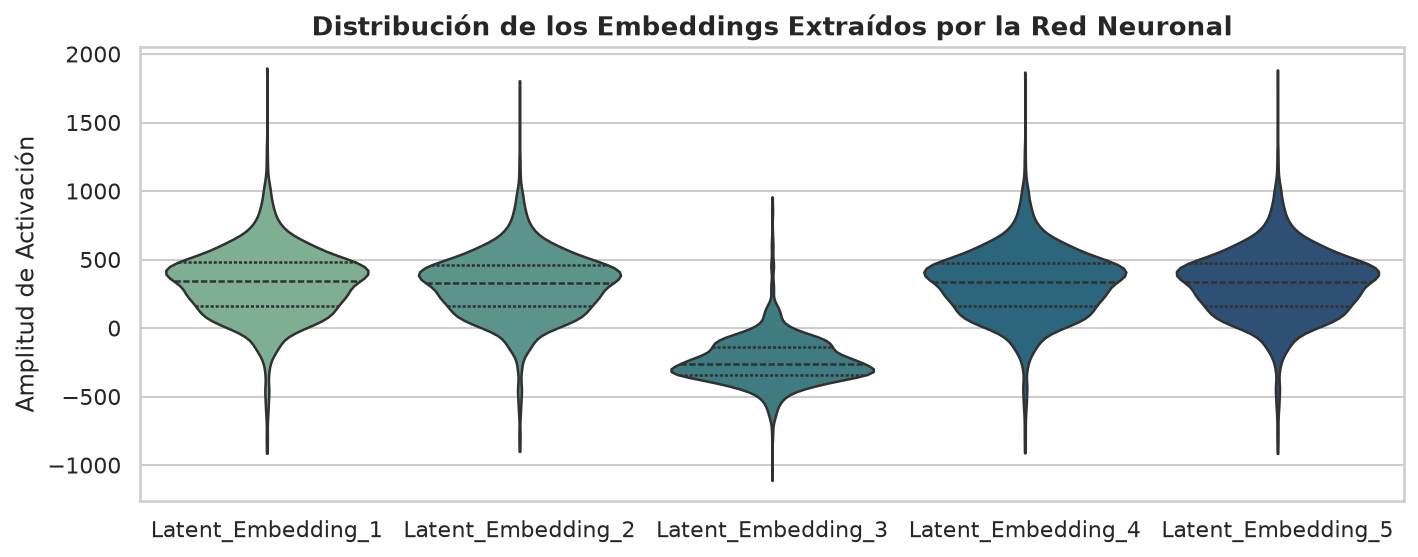

##### 1. Variación de las coordenadas

Las coordenadas mostradas tienen dispersión, pero eso no demuestra que aporten información predictiva. Hay que medir su utilidad y redundancia, por ejemplo mediante ablaciones y evaluación retenida.

##### 2. El signo no determina el significado

Una coordenada con mediana negativa no representa necesariamente términos sustractivos del objetivo. Las representaciones latentes pueden reparametrizarse y no están identificadas semánticamente por su signo. Para atribuirles una función hacen falta análisis adicionales.

##### 3. Escala y estabilidad

El rango de un violín describe los valores observados; no prueba estabilidad numérica ni que BatchNorm o AdamW hayan acotado los pesos. Deben inspeccionarse pérdidas, gradientes y valores no finitos durante el entrenamiento.

##### 4. Utilidad para CatBoost

Un embedding continuo permite buscar umbrales, pero una distribución amplia no garantiza cortes útiles ni independencia entre coordenadas. Comparar con atributos originales, categorías solas y red sola permite evaluar si la primera etapa aporta valor.

#### 3.6.6.2. Resumen SHAP

El gráfico de barras informa la media del valor absoluto de las atribuciones por característica, calculadas con el método nativo de CatBoost sobre el Pool. Resume magnitud, no dirección del efecto. La suma de las atribuciones individuales más la referencia recupera la salida del modelo. SHAP explica el modelo aprendido y no establece causalidad ni convierte automáticamente un embedding en un factor interpretable.

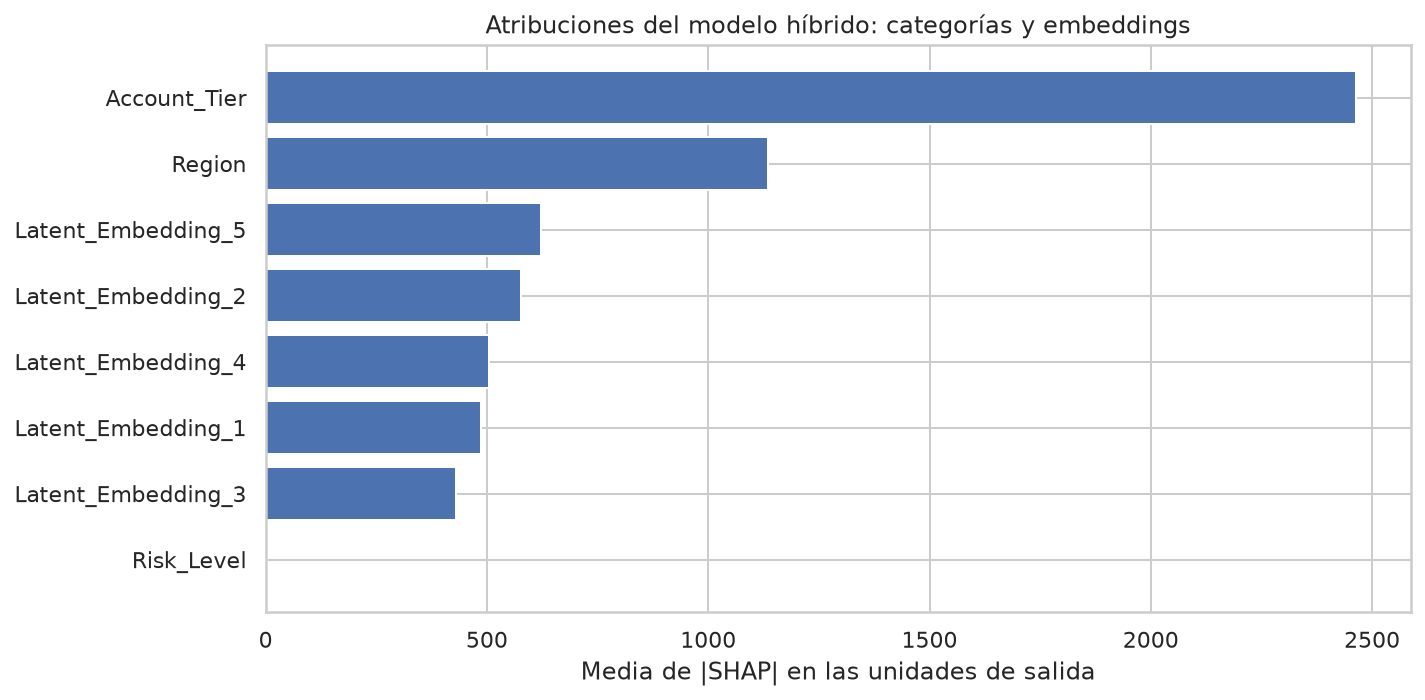

## Referencias y lecturas

- [CatBoost: unbiased boosting with categorical features · NeurIPS 2018](https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html)
- [Parámetros comunes · CatBoost](https://catboost.ai/docs/en/references/training-parameters/common)
- [Categorías · XGBoost](https://xgboost.readthedocs.io/en/stable/tutorials/categorical.html)
- [Categorías · LightGBM](https://lightgbm.readthedocs.io/en/stable/Advanced-Topics.html#categorical-feature-support)
- [Reproducibilidad · PyTorch](https://docs.pytorch.org/docs/stable/notes/randomness.html)

Referencias del material de origen: [tesis de grado](https://drive.google.com/file/d/1fxbhCJ6f9nTZXvzaqboVLrMFQE1AlXZv/view) y [Dive into Deep Learning](https://d2l.ai/). Los textos y figuras de terceros conservan sus créditos y condiciones.